In [1]:
import sys
import os
sys.path.append(os.path.abspath('../../'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from functions.preproc import *
from functions.cox import *

from sklearn.preprocessing import StandardScaler
from sksurv.linear_model import CoxPHSurvivalAnalysis
from sksurv.util import Surv
from lifelines import CoxPHFitter
from lifelines.statistics import proportional_hazard_test

import warnings
warnings.filterwarnings('ignore')

## Load Data

In [2]:
# Load the final dataset
dataset = pd.read_csv("../data/final/data_final.csv")

# Load feature lists
diagnosis_variables = []
with open("../data/final/diagnosis_final.txt", "r") as file:
    for line in file:
        diagnosis_variables.append(line.strip())

treatment_variables = []
with open("../data/final/treatment_final.txt", "r") as file:
    for line in file:
        treatment_variables.append(line.strip())

# Prepare survival dataset
if 'Unnamed: 0' in dataset.columns:
    survival_dataset = dataset.drop('Unnamed: 0', axis=1)
else:
    survival_dataset = dataset.copy()

feature_columns = treatment_variables + diagnosis_variables

print(f"Dataset shape: {survival_dataset.shape}")
print(f"Number of features: {len(feature_columns)}")
print(f"Events: {survival_dataset['Regional LN recurrence'].sum()}")
print(f"Censored: {(~survival_dataset['Regional LN recurrence'].astype(bool)).sum()}")

Dataset shape: (3230, 51)
Number of features: 48
Events: 36.0
Censored: 3194


In [11]:
dataset['Endocrine therapy performed'].value_counts()

Endocrine therapy performed
0    2671
1     559
Name: count, dtype: int64

## Handle Duplicate Patients

In [3]:
# Find duplicated patients
mask = survival_dataset.duplicated(subset='PERSON_ID', keep=False)

print(f"Duplicated patients: {mask.sum()}")

if mask.sum() > 0:
    # Keep row with lowest survival days for each patient
    to_remove = (
        survival_dataset[mask]
        .sort_values(['PERSON_ID', 'Survival days'], ascending=[True, True])
        .groupby('PERSON_ID')
        .head(-1)
        .index
    )
    
    survival_dataset = survival_dataset.drop(to_remove)
    print(f"Removed {len(to_remove)} duplicate entries")
    print(f"Final dataset shape: {survival_dataset.shape}")

Duplicated patients: 498
Removed 260 duplicate entries
Final dataset shape: (2970, 51)


## Prepare Data for Cox Model

In [4]:
# Prepare features and target
data_x = survival_dataset[feature_columns]

data_y = Surv.from_arrays(
    event=survival_dataset['Regional LN recurrence'],
    time=survival_dataset['Survival days']
)

# Scale features
scaler = StandardScaler()
data_x_scaled = scaler.fit_transform(data_x)
data_x_scaled = pd.DataFrame(data_x_scaled, columns=data_x.columns, index=data_x.index)

print("Data prepared for Cox model")

Data prepared for Cox model


## Fit Cox Model (using lifelines for PH testing)

In [5]:
# Prepare data for lifelines (requires DataFrame format)
df_cox = data_x_scaled.copy()
df_cox['event'] = survival_dataset['Regional LN recurrence'].values
df_cox['time'] = survival_dataset['Survival days'].values

# Fit Cox model
cph = CoxPHFitter()
cph.fit(df_cox, duration_col='time', event_col='event')

print("Cox model fitted successfully")
print(f"Concordance index: {cph.concordance_index_:.4f}")

Cox model fitted successfully
Concordance index: 0.9319


## PH assumption test

`proportional_hazard_test` checks correlation between Schoenfeld residuals and time (null: no correlation, i.e. PH holds). p > 0.05 means it holds, p < 0.05 means violated.

In [7]:
# Test proportional hazards assumption
ph_test_result = proportional_hazard_test(cph, df_cox, time_transform='rank')

print("\n=== PROPORTIONAL HAZARDS ASSUMPTION TEST ===")
print("\nTest statistics for each feature:")

# Get the summary DataFrame
ph_test_results = ph_test_result.summary

print(ph_test_results)

# Identify features that violate the PH assumption (p < 0.05)
violations = ph_test_results[ph_test_results['p'] < 0.05]

if len(violations) > 0:
    print(f"\n⚠️  WARNING: {len(violations)} features violate the PH assumption (p < 0.05):")
    print(violations[['test_statistic', 'p']].sort_values('p'))
else:
    print("\nAll features satisfy the PH assumption (p > 0.05)")

# Summary statistics
print(f"\nSummary:")
print(f"  - Total features tested: {len(ph_test_results)}")
print(f"  - Features violating PH (p < 0.05): {len(violations)}")
print(f"  - Percentage violating: {100 * len(violations) / len(ph_test_results):.1f}%")


=== PROPORTIONAL HAZARDS ASSUMPTION TEST ===

Test statistics for each feature:
                                                    test_statistic         p  \
Adjuvant chemotherapy                                 1.433051e-03  0.969803   
Adjuvant therapy with bio drugs                       1.933490e+00  0.164377   
Age                                                   8.056182e-02  0.776537   
Boost dose administered                               1.523526e+00  0.217087   
Chemotherapy performed                                5.209004e-01  0.470458   
Classification with respect to other lesions_2.0      5.976964e-05  0.993832   
Classification with respect to other lesions_3.0      1.739815e-01  0.676597   
Conventional RT fraction                              1.158220e-01  0.733611   
Disease extent_1.0                                    1.116970e-09  0.999973   
Disease extent_2.0                                    3.207759e-01  0.571142   
Endocrine therapy performed            

## Schoenfeld residual plots

Scaled residuals vs time for the features that violate PH. Flat trend = assumption holds.

Plotting Schoenfeld residuals for features with PH violations...


   Bootstrapping lowess lines. May take a moment...

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.



<lifelines.StatisticalResult: proportional_hazard_test>
 null_distribution = chi squared
degrees_of_freedom = 1
             model = <lifelines.CoxPHFitter: fitted with 2970 total observations, 2937 right-censored observations>
         test_name = proportional_hazard_test

---
                                                                test_statistic    p  -log2(p)
Adjuvant chemotherapy                                     km              0.01 0.91      0.14
                                                          rank            0.00 0.97      0.04
Adjuvant therapy with bio drugs                           km              0.32 0.57      0.80
                                                          rank            1.93 0.16      2.60
Age                                                       km              0.01 0.92      0.13
                                                          rank            0.08 0.78      0.36
Boost dose administered                                   km              0.17 0.68      0.56
                                                          rank            1.52 0.22      2.20
Chemotherapy performed                                    km              0.03 0.87      0.21
                                                          rank            0.52 0.47      1.09
Classification with respect to other lesions_2.0          km              0.01 0.90      0.15
                                                          rank            0.00 0.99      0.01
Classification with respect to other lesions_3.0          km              0.04 0.85      0.24
                                                          rank            0.17 0.68      0.56
Conventional RT fraction                                  km              0.01 0.92      0.12
                                                          rank            0.12 0.73      0.45
Disease extent_1.0                                        km              0.00 1.00      0.00
                                                          rank            0.00 1.00      0.00
Disease extent_2.0                                        km              0.18 0.67      0.58
                                                          rank            0.32 0.57      0.81
Endocrine therapy performed                               km              1.94 0.16      2.61
                                                          rank            7.48 0.01      7.33
Grade at CB_1.0                                           km              0.00 1.00      0.00
                                                          rank            0.00 1.00      0.00
Grade at CB_2.0                                           km              0.00 1.00      0.00
                                                          rank            0.00 1.00      0.00
Grade at CB_3.0                                           km              0.00 1.00      0.00
                                                          rank            0.00 1.00      0.00
Her2 overexpression (with immunohystochemistry) at CB_1.0 km              0.00 1.00      0.00
                                                          rank            0.00 1.00      0.00
Her2 overexpression (with immunohystochemistry) at CB_2.0 km              0.00 1.00      0.00
                                                          rank            0.00 1.00      0.00
Her2 overexpression (with immunohystochemistry) at CB_3.0 km              0.00 1.00      0.00
                                                          rank            0.00 1.00      0.00
Istotype at CB_1.0                                        km              0.06 0.80      0.31
                                                          rank            0.04 0.85      0.24
Istotype at CB_2.0                                        km              0.00 0.97      0.05
                                                          rank            0.00 0.98      0.03
Istotype at CB_3.0                                     



1. Variable 'Endocrine therapy performed' failed the non-proportional test: p-value is 0.0062.

   Advice: with so few unique values (only 2), you can include `strata=['Endocrine therapy
performed', ...]` in the call in `.fit`. See documentation in link [E] below.

---
[A]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html
[B]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Bin-variable-and-stratify-on-it
[C]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Introduce-time-varying-covariates
[D]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Modify-the-functional-form
[E]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Stratification



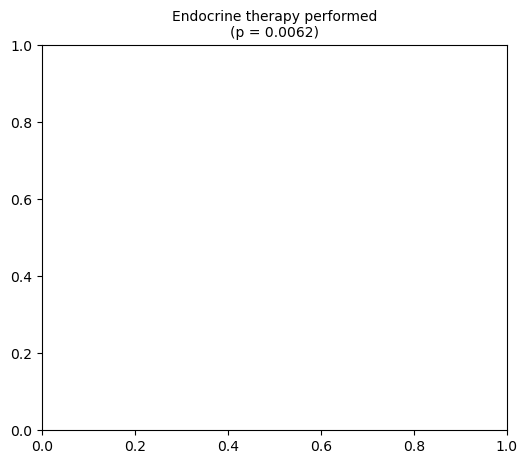

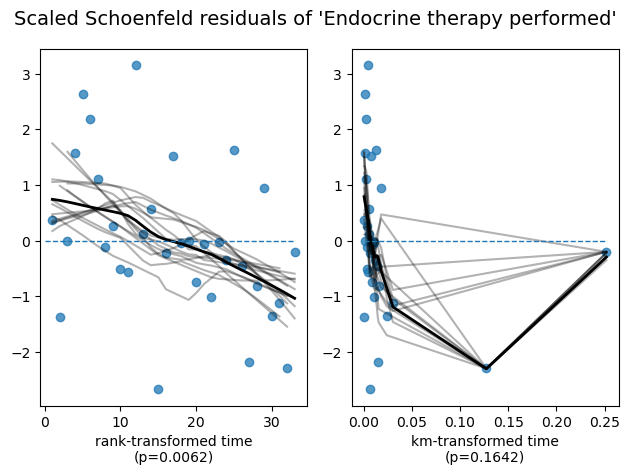

In [9]:
# Check proportional hazards visually using built-in plot
if len(violations) > 0:
    print("Plotting Schoenfeld residuals for features with PH violations...\n")
    
    # Plot up to 12 most significant violations
    features_to_plot = violations.sort_values('p').head(12).index.tolist()
    
    # Calculate grid dimensions
    n_features = len(features_to_plot)
    n_cols = min(3, n_features)
    n_rows = (n_features + n_cols - 1) // n_cols
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6*n_cols, 5*n_rows))
    
    if n_features == 1:
        axes = [axes]
    else:
        axes = axes.flatten()
    
    for idx, feature in enumerate(features_to_plot):
        ax = axes[idx]
        cph.check_assumptions(df_cox, p_value_threshold=0.05, 
                             show_plots=True, columns=[feature])
        ax.set_title(f"{feature}\n(p = {violations.loc[feature, 'p']:.4f})", fontsize=10)
    
    # Hide unused subplots
    for idx in range(n_features, len(axes)):
        axes[idx].axis('off')
    
    plt.tight_layout()
    plt.show()
else:
    print("No PH violations detected - skipping residual plots")

## Global Test

Test if the overall model satisfies the PH assumption.

In [10]:
# Global test
print("\n=== GLOBAL PROPORTIONAL HAZARDS TEST ===")
global_p = ph_test_results.loc['_GLOBAL', 'p']

print(f"Global test statistic: {ph_test_results.loc['_GLOBAL', 'test_statistic']:.4f}")
print(f"Global p-value: {global_p:.4f}")

if global_p < 0.05:
    print("\nThe overall model VIOLATES the proportional hazards assumption.")
    print("Consider:")
    print("  - Stratifying by violating variables")
    print("  - Adding time-varying coefficients")
    print("  - Using alternative models (e.g., accelerated failure time)")
else:
    print("\nThe overall model SATISFIES the proportional hazards assumption.")


=== GLOBAL PROPORTIONAL HAZARDS TEST ===


KeyError: '_GLOBAL'

## Export Detailed Results

In [ ]:
# Create detailed results dataframe
results_df = ph_test_results.copy()
results_df = results_df[results_df.index != '_GLOBAL']  # Remove global test
results_df['violates_ph'] = results_df['p'] < 0.05
results_df = results_df.sort_values('p')

print("\n=== TOP 20 FEATURES BY P-VALUE ===")
print(results_df[['test_statistic', 'p', 'violates_ph']].head(20))

# Save results
results_df.to_csv('schoenfeld_residuals_results.csv')
print("\nResults saved to 'schoenfeld_residuals_results.csv'")